# Notebook 02 · Representaciones dispersas y clasificación

**Proyecto:** Análisis de sentimiento y de dimensiones semánticas de la experiencia del huésped en reseñas de hoteles de lujo
**Autores:** Isabel Cristina Morales Parra – Jaime Esteban Bejarano Caldas

**Objetivo que cubre:** objetivo específico 3, en su componente de representaciones dispersas. Se comparan clasificadores de sentimiento construidos con bolsa de palabras (BoW) binaria, BoW con conteos y TF-IDF con unigramas y bigramas. Word2Vec se evalúa en el notebook 03, con la misma partición.

## 0. Configuración y partición de los datos

Se carga el corpus depurado y normalizado en el notebook 01 y se trabaja con el **escenario A** (positivo = 4–5; negativo = 1–2). Se reserva el 20 % de las reseñas como conjunto de prueba, con **partición estratificada**: la proporción de negativas (4 %) se conserva igual en entrenamiento y en prueba. Sin estratificación, con solo 650 negativas, el azar podría dejar en prueba una proporción distinta y sesgar la evaluación.

El conjunto de prueba no se usa para ninguna decisión del modelo: el ajuste de hiperparámetros se hace con validación cruzada sobre el conjunto de entrenamiento.

In [2]:
%load_ext autoreload
%autoreload 2

import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(RAIZ) not in sys.path:
    sys.path.append(str(RAIZ))
from src.evaluacion import metricas_clasificacion

RUTA_FIGURAS = RAIZ / "figures"
RUTA_RESULTADOS = RAIZ / "results"
SEMILLA = 42
sns.set_theme(style="whitegrid", palette="deep")

# --- Corpus del escenario A ---
df_en = pd.read_csv(RAIZ / "data" / "processed" / "resenas_en_depuradas.csv")
corpus_A = df_en.dropna(subset=["polaridad_A"]).reset_index(drop=True)

X_entrena, X_prueba, y_entrena, y_prueba = train_test_split(
    corpus_A["texto_limpio"], corpus_A["polaridad_A"],
    test_size=0.20, stratify=corpus_A["polaridad_A"], random_state=SEMILLA)

# Se guardan los índices de prueba para que el notebook 03 (Word2Vec) use exactamente la misma partición
pd.Series(X_prueba.index, name="indice").to_csv(RUTA_RESULTADOS / "02_indices_prueba.csv", index=False)

particion = pd.DataFrame({
    "Reseñas": [len(y_entrena), len(y_prueba)],
    "Negativas": [(y_entrena == "negativo").sum(), (y_prueba == "negativo").sum()],
}, index=["Entrenamiento", "Prueba"])
particion["% negativas"] = (particion["Negativas"] / particion["Reseñas"] * 100).round(2)
display(particion)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


,Reseñas,Negativas,% negativas
Entrenamiento,13150,520,3.95
Prueba,3288,130,3.95


**Resultado.** El escenario A cuenta con 16.438 reseñas: **13.150 para entrenamiento** (520 negativas) y **3.288 para prueba** (130 negativas). La proporción de negativas es idéntica en ambos conjuntos (3,95 %), como se esperaba de la partición estratificada.

**Implicación.** La evaluación final depende de solo 130 reseñas negativas: cada una equivale a 0,77 puntos porcentuales del *recall* negativo. Las diferencias pequeñas entre modelos (uno o dos puntos) deben interpretarse con cautela, porque pueden deberse a unas pocas reseñas. Por eso se reporta también el F1-macro de la validación cruzada, que se calcula sobre más datos.

## 1. Comparación de representaciones dispersas

Se comparan cuatro modelos sobre la misma partición:

| Modelo | Representación | Qué captura |
|:--|:--|:--|
| **Línea base** | — | Predice siempre la clase mayoritaria («positivo»). Es el punto de partida que cualquier modelo debe superar |
| **BoW binario** | 1 si la palabra aparece en la reseña, 0 si no | Presencia de palabras |
| **BoW conteos** | Número de veces que aparece la palabra | Presencia y repetición; es sensible a la longitud de la reseña |
| **TF-IDF (1–2)** | Frecuencia del término ponderada por su rareza en el corpus, con unigramas y bigramas | Peso de las palabras informativas y expresiones de dos palabras como *not clean* |

**Clasificador:** regresión logística con `class_weight="balanced"`, que pondera los errores en la clase negativa en proporción inversa a su frecuencia (≈ 24 veces más). **Ajuste:** el hiperparámetro de regularización `C` se elige por validación cruzada estratificada de 5 particiones sobre el conjunto de entrenamiento, maximizando el F1-macro. **Vocabulario:** se descartan los términos que aparecen en menos de 3 reseñas (`min_df=3`), lo que elimina la mayoría de los *hapax legomena*.

,F1-macro,Exactitud balanceada,Precisión (negativo),Recall (negativo),Exactitud (referencia),F1-macro (validación cruzada),C elegido,Vocabulario,Tiempo de ajuste (s)
Línea base,0.490,0.500,0.000,0.000,0.960,NaN,NaN,NaN,NaN
BoW binario,0.884,0.916,0.719,0.846,0.981,0.877,1.0,7098.0,11.197
BoW conteos,0.886,0.891,0.769,0.792,0.982,0.884,3.0,7098.0,4.242
TF-IDF (1–2),0.918,0.927,0.824,0.862,0.987,0.904,30.0,36153.0,7.896


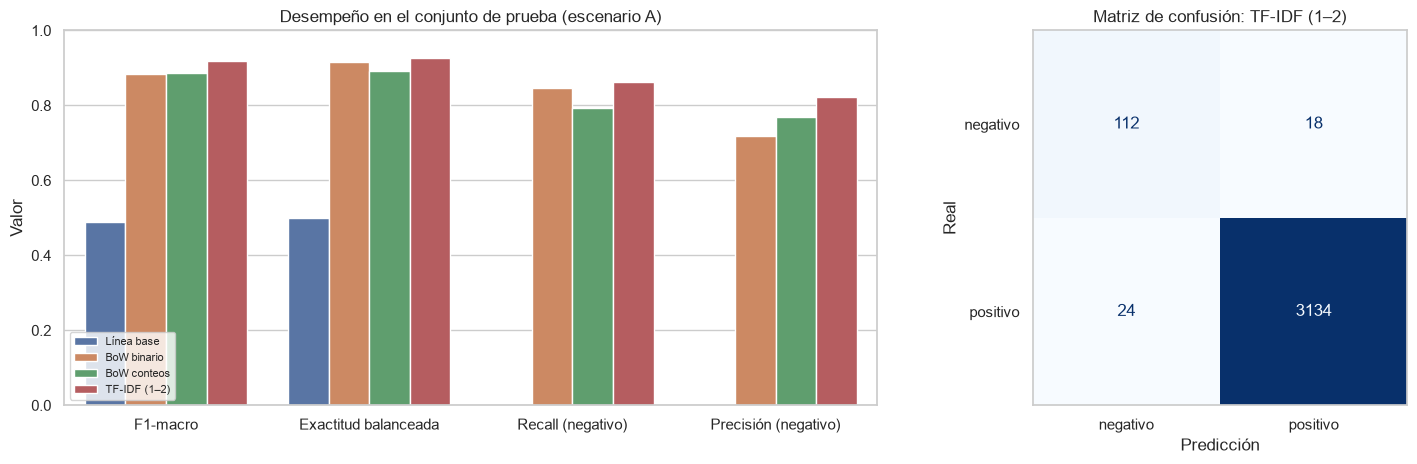

In [3]:
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline

validacion = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)

representaciones = {
    "BoW binario":  CountVectorizer(binary=True, min_df=3, token_pattern=r"\S+"),
    "BoW conteos":  CountVectorizer(min_df=3, token_pattern=r"\S+"),
    "TF-IDF (1–2)": TfidfVectorizer(ngram_range=(1, 2), min_df=3, sublinear_tf=True, token_pattern=r"\S+"),
}

resultados, modelos = {}, {}

# --- Línea base ---
base = DummyClassifier(strategy="most_frequent").fit(X_entrena, y_entrena)
resultados["Línea base"] = metricas_clasificacion(y_prueba, base.predict(X_prueba))

# --- Representaciones dispersas + regresión logística ---
for nombre, vectorizador in representaciones.items():
    flujo = Pipeline([
        ("representacion", vectorizador),
        ("clasificador", LogisticRegression(class_weight="balanced", solver="liblinear", max_iter=2000)),
    ])
    busqueda = GridSearchCV(flujo, {"clasificador__C": [0.1, 0.3, 1, 3, 10, 30]},
                            scoring="f1_macro", cv=validacion, n_jobs=-1)
    inicio = time.perf_counter()
    busqueda.fit(X_entrena, y_entrena)
    duracion = time.perf_counter() - inicio

    resultados[nombre] = metricas_clasificacion(y_prueba, busqueda.predict(X_prueba))
    resultados[nombre].update({
        "F1-macro (validación cruzada)": busqueda.best_score_,
        "C elegido": busqueda.best_params_["clasificador__C"],
        "Vocabulario": len(busqueda.best_estimator_.named_steps["representacion"].vocabulary_),
        "Tiempo de ajuste (s)": duracion,
    })
    modelos[nombre] = busqueda.best_estimator_

tabla_resultados = pd.DataFrame(resultados).T
display(tabla_resultados.round(3))
tabla_resultados.to_csv(RUTA_RESULTADOS / "02_comparacion_representaciones_dispersas.csv")

# --- Figura: métricas principales + matriz de confusión del mejor modelo ---
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={"width_ratios": [1.6, 1]})

metricas_grafica = ["F1-macro", "Exactitud balanceada", "Recall (negativo)", "Precisión (negativo)"]
datos_grafica = tabla_resultados[metricas_grafica].reset_index(names="Modelo").melt(
    id_vars="Modelo", var_name="Métrica", value_name="Valor")
sns.barplot(data=datos_grafica, x="Métrica", y="Valor", hue="Modelo", ax=axes[0])
axes[0].set(title="Desempeño en el conjunto de prueba (escenario A)", ylim=(0, 1), xlabel="")
axes[0].legend(loc="lower left", fontsize=8)

mejor = tabla_resultados["F1-macro"].drop("Línea base").idxmax()
ConfusionMatrixDisplay.from_estimator(modelos[mejor], X_prueba, y_prueba, cmap="Blues",
                                      colorbar=False, ax=axes[1])
axes[1].set(title=f"Matriz de confusión: {mejor}", xlabel="Predicción", ylabel="Real")
axes[1].grid(False)

plt.tight_layout()
fig.savefig(RUTA_FIGURAS / "02_comparacion_dispersas.png", dpi=150, bbox_inches="tight")
plt.show()

**Resultado.**

| Modelo | F1-macro | Exactitud balanceada | *Recall* negativo | Precisión negativa | Exactitud |
|:--|--:|--:|--:|--:|--:|
| Línea base | 0,490 | 0,500 | 0,000 | 0,000 | 0,960 |
| BoW binario | 0,884 | 0,916 | 0,846 | 0,719 | 0,981 |
| BoW conteos | 0,886 | 0,891 | 0,792 | 0,769 | 0,982 |
| **TF-IDF (1–2)** | **0,918** | **0,927** | **0,862** | **0,824** | **0,987** |

1. **La exactitud engaña.** La línea base alcanza 96 % de exactitud sin detectar una sola reseña negativa. Entre los modelos reales la exactitud apenas varía (0,981–0,987), mientras que el F1-macro y el *recall* negativo sí muestran diferencias. Esto confirma la elección de métricas.
2. **TF-IDF con bigramas es la mejor representación** en todas las métricas. Detecta 112 de las 130 reseñas negativas de prueba, y de las 136 que marca como negativas, 112 lo son. Su ventaja proviene de dos fuentes: la ponderación IDF, que resta peso a las palabras que aparecen en todas las reseñas (*hotel*, *room*), y los bigramas, que capturan expresiones como *not clean* o *not worth*, identificadas como las más distintivas en el notebook 01.
3. **BoW conteos tiene el menor *recall* negativo (0,792).** Es coherente con la hipótesis del notebook 01: los conteos crecen con la longitud de la reseña, y la longitud introduce ruido. BoW binario y TF-IDF con `sublinear_tf` atenúan ese efecto.
4. **Los resultados son consistentes.** El F1-macro en prueba (0,918) es cercano al de la validación cruzada (0,904): el modelo no está sobreajustado a la partición de prueba. El valor `C = 30` se verificó dentro de una grilla extendida hasta 100.

**Errores del mejor modelo:** 18 reseñas negativas clasificadas como positivas (falsos negativos) y 24 positivas clasificadas como negativas (falsos positivos). Se analizan en el notebook 05.

## 2. Interpretación del modelo: ¿qué aprendió TF-IDF?

La regresión logística asigna un coeficiente a cada término del vocabulario. Como el modelo estima la probabilidad de la clase «positivo», un **coeficiente negativo** empuja la predicción hacia «negativo» y uno **positivo** hacia «positivo». Revisar los términos con los coeficientes más extremos permite verificar que el modelo aprendió señales de sentimiento razonables, y no artefactos del corpus.

Clases del modelo: ['negativo' 'positivo']


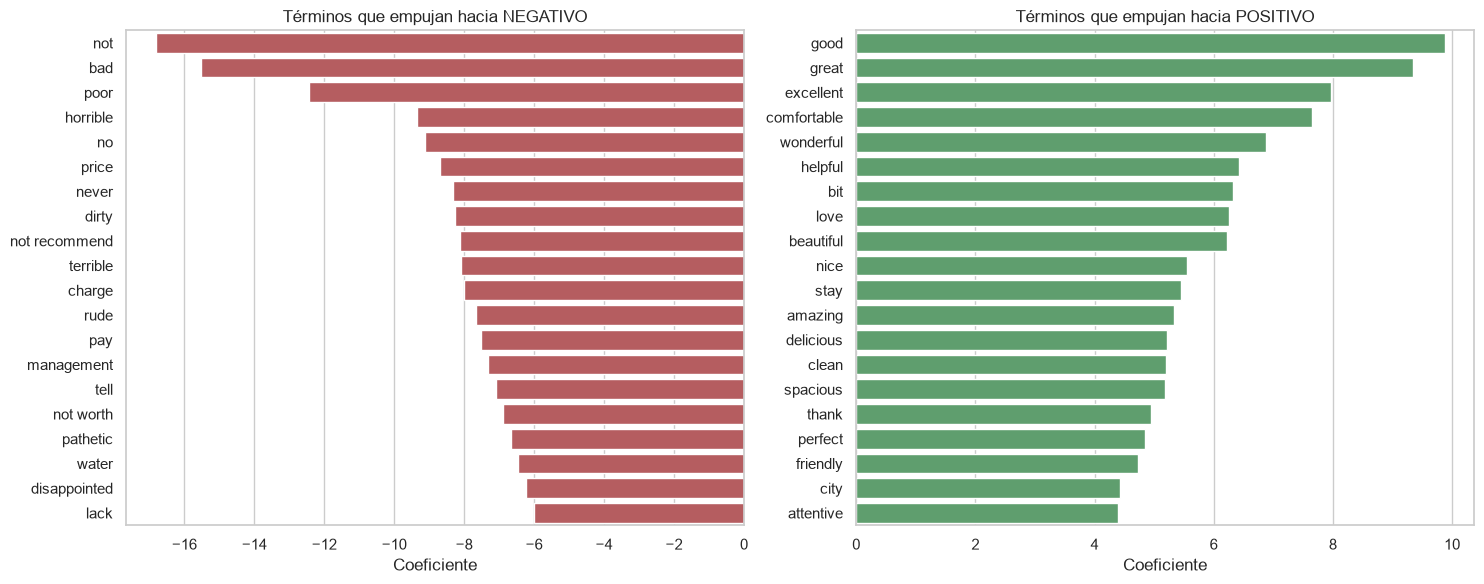

In [4]:
modelo_tfidf = modelos["TF-IDF (1–2)"]
vocabulario = modelo_tfidf.named_steps["representacion"].get_feature_names_out()
coeficientes = modelo_tfidf.named_steps["clasificador"].coef_[0]
print("Clases del modelo:", modelo_tfidf.named_steps["clasificador"].classes_)

coef = pd.DataFrame({"termino": vocabulario, "coeficiente": coeficientes})
top_neg = coef.nsmallest(20, "coeficiente")
top_pos = coef.nlargest(20, "coeficiente")

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
sns.barplot(data=top_neg, y="termino", x="coeficiente", color="#C44E52", ax=axes[0])
axes[0].set(title="Términos que empujan hacia NEGATIVO", xlabel="Coeficiente", ylabel="")
sns.barplot(data=top_pos, y="termino", x="coeficiente", color="#55A868", ax=axes[1])
axes[1].set(title="Términos que empujan hacia POSITIVO", xlabel="Coeficiente", ylabel="")
plt.tight_layout()
fig.savefig(RUTA_FIGURAS / "02_coeficientes_tfidf.png", dpi=150, bbox_inches="tight")
plt.show()

coef.sort_values("coeficiente").to_csv(RUTA_RESULTADOS / "02_coeficientes_tfidf.csv", index=False)

**Resultado.** El modelo aprendió señales de sentimiento coherentes con el análisis exploratorio.

- **La negación es la señal negativa más fuerte del modelo:** *not* tiene el coeficiente más extremo (≈ −17), y también aparecen *no*, *never*, *not recommend* y *not worth*. Esto confirma, desde el modelo, la decisión de conservar las negaciones durante la normalización.
- **Las señales negativas reproducen las dos dimensiones del notebook 01:**
  - **transaccional:** *price*, *charge*, *pay*, *management*, *tell*;
  - **higiene y mantenimiento:** *dirty*, *water*, *lack*.
- **Las señales positivas son adjetivos de calidad** (*good*, *great*, *excellent*, *wonderful*, *perfect*) y de trato (*helpful*, *friendly*, *attentive*), además de atributos del espacio (*comfortable*, *clean*, *spacious*).
- **Caso particular: *bit*.** Su coeficiente positivo sorprende, pero refleja un patrón del lenguaje de las reseñas favorables: «*a bit* noisy», «*a bit* far from the center». Es una crítica atenuada, propia de reseñas de 4 estrellas que, en conjunto, son positivas. Quien tuvo una mala experiencia no matiza.
- **No aparecen nombres de hoteles ni de empleados entre los 20 términos más influyentes,** a diferencia del análisis de frecuencias. La regularización de la regresión logística reduce el peso de términos poco frecuentes. Aun así, se revisará en el análisis de errores si influyen en casos concretos.